# Labor 1 – Verarbeitung und Darstellung der Messdaten (MainCode1)

## Import all libraries

In [1]:
#import libraries
import pandas as pd
import numpy as np
import scipy.signal as sci
import matplotlib.pyplot as plot

## Aufgabe 4 (a): 4 Sekunden der ersten Messung (Lab1Code1, ODR 12.5 Hz)

Lab1Code1 gibt Rohwerte aus. Bei ±2 g gilt laut Datenblatt 1024 LSB/g.

In [2]:
#import recorded .csv File and store it in a dataframe
df4 = pd.read_csv(r'data/IMU_A4_Lab1Code1_roh.csv', sep=r'\s+')

#convert time from ms into s
df4['Time'] = df4['Time'].div(1000)

#convert raw values into g (±2 g -> 1024 LSB/g)
df4[['X', 'Y', 'Z']] = df4[['X', 'Y', 'Z']].div(1024)

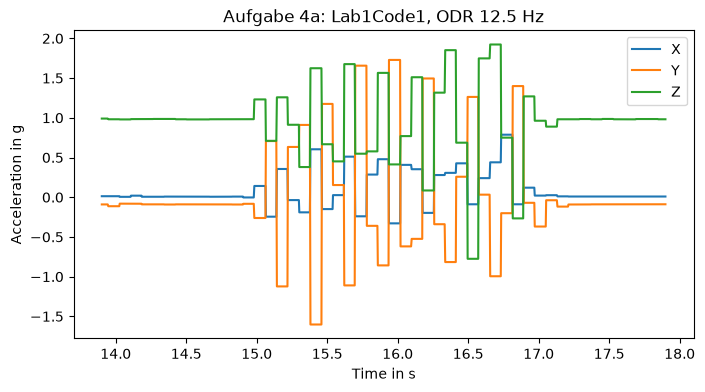

In [3]:
#cut out 4 seconds (movement)
df4_cut = df4[(df4['Time'] >= 13.9) & (df4['Time'] < 17.9)]

# display data
df4_cut.plot(x = 'Time', y = ['X', 'Y', 'Z'], ylabel='Acceleration in g',
             xlabel='Time in s', figsize= [8, 4], title="Aufgabe 4a: Lab1Code1, ODR 12.5 Hz")
plot.savefig('figures/A4a_12_5Hz.png', dpi=150)

## Aufgabe 5: Wiederholung mit ODR 100 Hz und Vergleich

Geändert in `Lab1Code1_modifiziert.ino`: `accel.setODR(BMA400_ODR_100HZ)` und `delay(10)`.

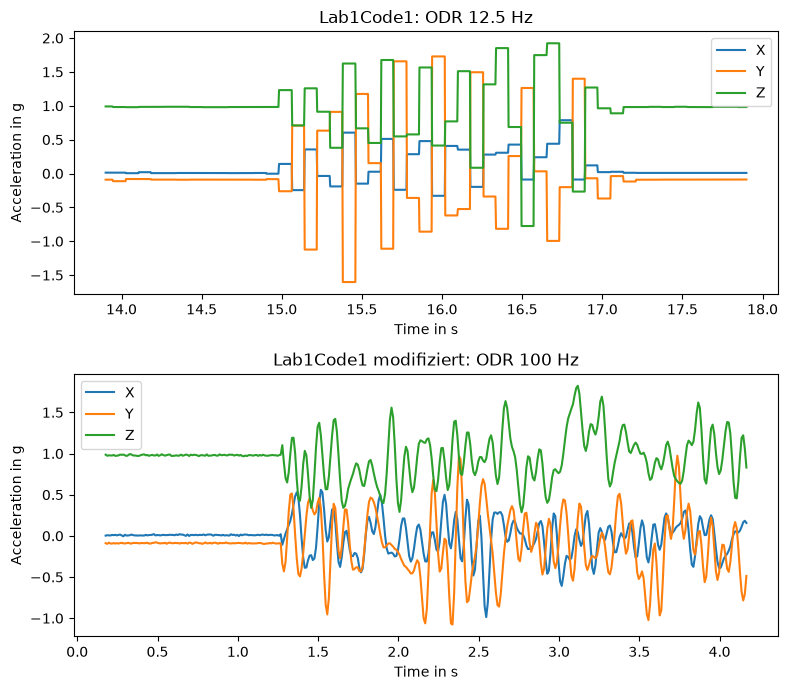

In [4]:
df5 = pd.read_csv(r'data/IMU_A5_Lab1Code1mod_100Hz.csv', sep=r'\s+')
df5['Time'] = df5['Time'].div(1000)

#plot both measurements (4 s each) below each other
fig, axs = plot.subplots(2, 1, figsize= [8, 7])
df4_cut.plot(x = 'Time', y = ['X', 'Y', 'Z'], ax=axs[0], ylabel='Acceleration in g',
             xlabel='Time in s', title="Lab1Code1: ODR 12.5 Hz")
df5.plot(x = 'Time', y = ['X', 'Y', 'Z'], ax=axs[1], ylabel='Acceleration in g',
         xlabel='Time in s', title="Lab1Code1 modifiziert: ODR 100 Hz")
plot.tight_layout()
plot.savefig('figures/A5_Vergleich_12_5Hz_100Hz.png', dpi=150)

## Aufgabe 6 (a): Sensor in allen 6 Lagen (je 10 s)

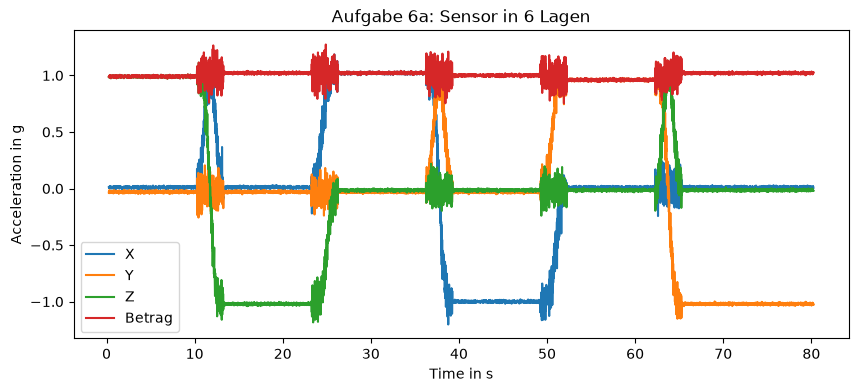

In [5]:
df6 = pd.read_csv(r'data/IMU_A6_Lagen.csv', sep=r'\s+')
df6['Time'] = df6['Time'].div(1000)

#magnitude of acceleration, should be 1 g at rest
df6['Betrag'] = np.sqrt(df6['X']**2 + df6['Y']**2 + df6['Z']**2)

df6.plot(x = 'Time', y = ['X', 'Y', 'Z', 'Betrag'], ylabel='Acceleration in g',
         xlabel='Time in s', figsize= [10, 4], title="Aufgabe 6a: Sensor in 6 Lagen")
plot.savefig('figures/A6a_6_Lagen.png', dpi=150)

## Aufgabe 6 (b): Mittelwerte in den Ruhephasen

Zeitfenster aus dem Plot abgelesen.

In [6]:
lagen = {'Z oben': (1, 9), 'Z unten': (14, 22), 'X oben': (27, 35),
         'X unten': (40, 48), 'Y oben': (53, 61), 'Y unten': (66, 79)}

for name, (t0, t1) in lagen.items():
    ruhe = df6[(df6['Time'] > t0) & (df6['Time'] < t1)]
    print(name, ruhe[['X', 'Y', 'Z', 'Betrag']].mean().round(3).to_dict())

Z oben {'X': 0.01, 'Y': -0.03, 'Z': 0.99, 'Betrag': 0.991}
Z unten {'X': 0.01, 'Y': -0.029, 'Z': -1.02, 'Betrag': 1.02}
X oben {'X': 1.02, 'Y': -0.03, 'Z': -0.015, 'Betrag': 1.021}
X unten {'X': -1.0, 'Y': -0.03, 'Z': -0.015, 'Betrag': 1.0}
Y oben {'X': 0.01, 'Y': 0.96, 'Z': -0.015, 'Betrag': 0.961}
Y unten {'X': 0.01, 'Y': -1.02, 'Z': -0.015, 'Betrag': 1.021}


## Aufgabe 7: Gefilterte gegen ungefilterte Daten

Butterworth-Tiefpass 4. Ordnung mit 5 Hz Grenzfrequenz. Mit `filtfilt` wird vorwärts und rückwärts gefiltert, dadurch gibt es keine Phasenverschiebung.

In [7]:
# Setting up a butterworth filter
def butter_lowpass(cutoff, fs, order=4):
    # nyq: Nyquist Theorem
    nyq = 0.5 * fs
    b, a = sci.butter(order, cutoff / nyq, 'lowpass')
    return b, a

def butter_lowpass_filter(signal, cutoff, fs, order=4):
    #use filtfilt for a zero-phase filtering
    b, a = butter_lowpass(cutoff, fs, order)
    return sci.filtfilt(b, a, signal, axis=0)

Std Z in Ruhe ungefiltert: 6.0 mg
Std Z in Ruhe gefiltert:   1.6 mg


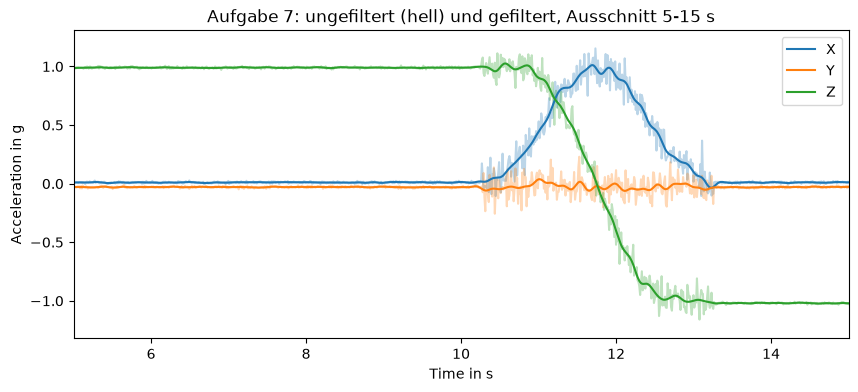

In [8]:
fs6 = (len(df6) - 1) / (df6['Time'].iloc[-1] - df6['Time'].iloc[0])

df6_filt = df6.copy()
df6_filt[['X', 'Y', 'Z']] = butter_lowpass_filter(df6[['X', 'Y', 'Z']], 5, fs6)

fig, ax = plot.subplots(figsize= [10, 4])
df6.plot(x = 'Time', y = ['X', 'Y', 'Z'], ax=ax, alpha=0.3, legend=False)
df6_filt.plot(x = 'Time', y = ['X', 'Y', 'Z'], ax=ax, color=['C0', 'C1', 'C2'])
ax.set_xlim(5, 15)
ax.set_ylabel('Acceleration in g')
ax.set_xlabel('Time in s')
ax.set_title('Aufgabe 7: ungefiltert (hell) und gefiltert, Ausschnitt 5-15 s')
plot.savefig('figures/A7_Filter.png', dpi=150)

ruhe = (df6['Time'] > 1) & (df6['Time'] < 9)
print('Std Z in Ruhe ungefiltert:', round(df6['Z'][ruhe].std() * 1000, 1), 'mg')
print('Std Z in Ruhe gefiltert:  ', round(df6_filt['Z'][ruhe].std() * 1000, 1), 'mg')

## Aufgabe 8: Abtastfrequenz (Mittelwert und Abweichung)

Aus den `millis()`-Zeitstempeln: $f_s = 1/\overline{\Delta t}$ und $\sigma_{f_s} \approx \sigma_{\Delta t} / \overline{\Delta t}^2$.

A4 (12.5 Hz): dt = 3.19 ± 0.47 ms, fs = 313.2 ± 45.8 Hz
A5 (100 Hz): dt = 10.00 ± 0.00 ms, fs = 100.0 ± 0.0 Hz
A6 (100 Hz): dt = 11.10 ± 0.46 ms, fs = 90.1 ± 3.7 Hz


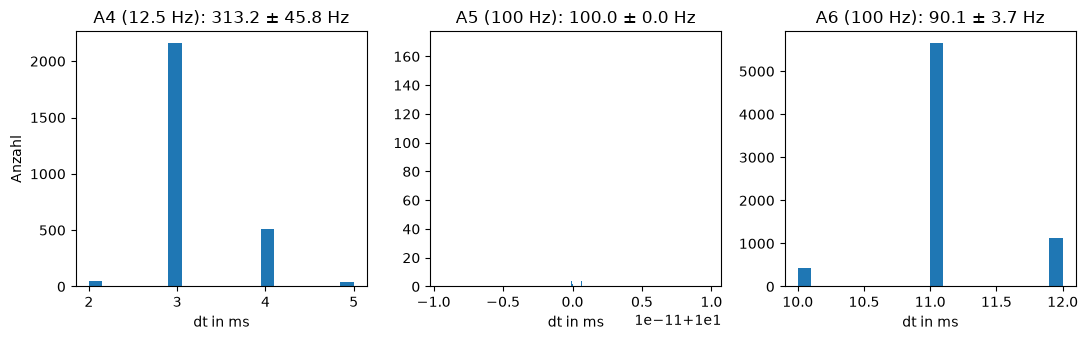

In [9]:
messungen = {'A4 (12.5 Hz)': df4, 'A5 (100 Hz)': df5, 'A6 (100 Hz)': df6}

fig, axs = plot.subplots(1, 3, figsize= [11, 3.5])
for ax, (name, df) in zip(axs, messungen.items()):
    dt = df['Time'].diff().dropna()
    fs_mean = 1 / dt.mean()
    fs_std = dt.std() / dt.mean()**2
    print(f'{name}: dt = {dt.mean()*1000:.2f} ± {dt.std()*1000:.2f} ms, fs = {fs_mean:.1f} ± {fs_std:.1f} Hz')

    ax.hist(dt * 1000, bins=20)
    ax.set_title(f'{name}: {fs_mean:.1f} ± {fs_std:.1f} Hz')
    ax.set_xlabel('dt in ms')
axs[0].set_ylabel('Anzahl')
plot.tight_layout()
plot.savefig('figures/A8_Abtastfrequenz.png', dpi=150)

In [10]:
#A4: sensor only delivers new values with 12.5 Hz, the rest are repeated lines
neu = df4[['X', 'Y', 'Z']].diff().abs().sum(axis=1) > 0
print('A4 neue Sensorwerte:', round(1 / df4['Time'][neu].diff().median(), 1), 'Hz')

A4 neue Sensorwerte: 12.5 Hz
